# EDA

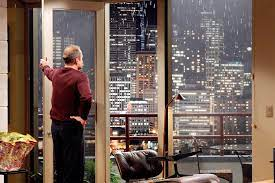

## Cleaning Data

### Imports and loading data

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()
pd.set_option("display.float_format", lambda x: "%.3f" % x)

We import the data from the CSV file:

In [2]:
df = pd.read_csv("data/eda.csv")

### Prepare data

Let's look at it to see if it is reasonably clean.

In [3]:
# df.describe()
# df.info()
df.head()

,date,price,house_id,id,id.1,bedrooms,bathrooms,sqft_living,sqft_lot,floors,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2014-10-13,221900.000,7129300520,1,7129300520,3.000,1.000,1180.000,5650.000,1.000,...,7,1180.000,0.000,1955,0.000,98178,47.511,-122.257,1340.000,5650.000
1,2014-12-09,538000.000,6414100192,2,6414100192,3.000,2.250,2570.000,7242.000,2.000,...,7,2170.000,400.000,1951,19910.000,98125,47.721,-122.319,1690.000,7639.000
2,2015-02-25,180000.000,5631500400,3,5631500400,2.000,1.000,770.000,10000.000,1.000,...,6,770.000,0.000,1933,NaN,98028,47.738,-122.233,2720.000,8062.000
3,2014-12-09,604000.000,2487200875,4,2487200875,4.000,3.000,1960.000,5000.000,1.000,...,7,1050.000,910.000,1965,0.000,98136,47.521,-122.393,1360.000,5000.000
4,2015-02-18,510000.000,1954400510,5,1954400510,3.000,2.000,1680.000,8080.000,1.000,...,8,1680.000,0.000,1987,0.000,98074,47.617,-122.045,1800.000,7503.000


Because there is a duplicated column, we get rid of id.1

In [4]:
# df = df.drop(columns=['house_id','id','id.1'])
df = df.drop(columns=['id.1'])

In [5]:
df.house_id.nunique()

21420

Since all column names seem to be lowercase and without empty spaces, we let them as is.

I might come back there later if the column names are not satisfactory or descriptive enough.

In [6]:
df .describe()

,price,house_id,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,19206.000,21534.000,...,21597.000,21597.000,21145.000,21597.000,17749.000,21597.000,21597.000,21597.000,21597.000,21597.000
mean,540296.574,4580474287.771,10799.000,3.373,2.116,2080.322,15099.409,1.494,0.008,0.234,...,7.658,1788.597,291.857,1971.000,836.651,98077.952,47.560,-122.214,1986.620,12758.284
std,367368.140,2876735715.748,6234.661,0.926,0.769,918.106,41412.637,0.540,0.087,0.766,...,1.173,827.760,442.491,29.375,4000.111,53.513,0.139,0.141,685.230,27274.442
min,78000.000,1000102.000,1.000,1.000,0.500,370.000,520.000,1.000,0.000,0.000,...,3.000,370.000,0.000,1900.000,0.000,98001.000,47.156,-122.519,399.000,651.000
25%,322000.000,2123049175.000,5400.000,3.000,1.750,1430.000,5040.000,1.000,0.000,0.000,...,7.000,1190.000,0.000,1951.000,0.000,98033.000,47.471,-122.328,1490.000,5100.000
50%,450000.000,3904930410.000,10799.000,3.000,2.250,1910.000,7618.000,1.500,0.000,0.000,...,7.000,1560.000,0.000,1975.000,0.000,98065.000,47.572,-122.231,1840.000,7620.000
75%,645000.000,7308900490.000,16198.000,4.000,2.500,2550.000,10685.000,2.000,0.000,0.000,...,8.000,2210.000,560.000,1997.000,0.000,98118.000,47.678,-122.125,2360.000,10083.000
max,7700000.000,9900000190.000,21597.000,33.000,8.000,13540.000,1651359.000,3.500,1.000,4.000,...,13.000,9410.000,4820.000,2015.000,20150.000,98199.000,47.778,-121.315,6210.000,871200.000


### Check duplicates

It seems there are no duplicates:

In [7]:
df.duplicated().value_counts()

False    21597
Name: count, dtype: int64

We also want to make sure that no transaction was duplicated, so for this we check if on the same date, the same house was sold. It turns out that it is not the case, so we're clean.

In [56]:
df[df.duplicated(subset=['house_id', 'date'], keep=False)]

,date,price,house_id,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15


### Check data types

We look at the data types:

In [31]:
df.dtypes

date             datetime64[us]
price                   float64
house_id                  int64
id                        int64
bedrooms                  Int64
bathrooms               float64
sqft_living             float64
sqft_lot                float64
floors                  float64
waterfront                 bool
view                      Int64
condition                 int64
grade                     int64
sqft_above              float64
sqft_basement           float64
yr_built                  int64
yr_renovated              Int64
zipcode                   int64
lat                     float64
long                    float64
sqft_living15           float64
sqft_lot15              float64
dtype: object

#### date

So, the only obvious problem is the date that is a string and could rather be a datetime:

In [9]:
df['date'] = pd.to_datetime(df['date'], format="%Y-%m-%d")

#### rooms & floors

Some fields should be integer by nature:
* bedrooms
* bathrooms
* floors

so we'll check what the different values are for those columns.

In [10]:
print("unique bedrooms numbers:", df.bedrooms.unique())
print("unique bathrooms numbers:", df.bathrooms.unique())
print("unique floors numbers:", df.floors.unique())

unique bedrooms numbers: [ 3.  2.  4.  5.  1.  6.  7.  8.  9. 11. 10. 33.]
unique bathrooms numbers: [1.   2.25 3.   2.   4.5  1.5  2.5  1.75 2.75 3.25 4.   3.5  0.75 4.75
 5.   4.25 3.75 1.25 5.25 6.   0.5  5.5  6.75 5.75 8.   7.5  7.75 6.25
 6.5 ]
unique floors numbers: [1.  2.  1.5 3.  2.5 3.5]


So let's start with the bedrooms. Obviously, this 33 feels fishy.

We'll build a graph to see the occurrences of each bedroom count.

In [11]:
df['bedrooms'].value_counts().sort_index()

bedrooms
1.000      196
2.000     2760
3.000     9824
4.000     6882
5.000     1601
6.000      272
7.000       38
8.000       13
9.000        6
10.000       3
11.000       1
33.000       1
Name: count, dtype: int64

Indeed, there's only one apartment with 33 rooms, it's probably a typo, so we'll check the typical sqft associated to each bedroom count.

In [12]:
room_comparison = df.groupby('bedrooms')['sqft_living'].agg(['mean', 'median', 'count'])
print(room_comparison)

             mean   median  count
bedrooms                         
1.000     888.153  790.000    196
2.000    1239.753 1140.000   2760
3.000    1805.837 1680.000   9824
4.000    2554.650 2410.000   6882
5.000    3047.545 2870.000   1601
6.000    3284.342 2955.000    272
7.000    3974.211 3335.000     38
8.000    3800.000 3840.000     13
9.000    3775.000 3755.000      6
10.000   3706.667 3610.000      3
11.000   3000.000 3000.000      1
33.000   1620.000 1620.000      1


So it appears the 33 bedrooms apartment belongs to the category 3 bedrooms, definitely a typo and we can safely assume it's actually a 3 bedrooms apartment. So we'll change it to the right value.

In [13]:
df['bedrooms'] = df['bedrooms'].replace(33,3)

Now, we'll change the type of the bedrooms to integer, since that's what they are.

In [14]:
df['bedrooms'] = df['bedrooms'].astype('Int64')

After some research, it turns out that float are used for bathrooms and floors because in real estate data, fractional values for bathrooms and floors are actually intentional standards, not formatting mistakes, so I should let it the way it is.


Bathrooms (American Real Estate Standard)

In US real estate, a "full bathroom" consists of four components: a toilet, a sink, a bathtub, and a shower. Values are broken down fractionally based on what is missing:
* 1.0 (Full Bath): Has all four components.
* 0.5 (Half Bath / Powder Room): Has only a toilet and a sink (no shower or tub).
* 0.75 (Three-Quarter Bath): Has a toilet, a sink, and a shower, but no bathtub.
* 1.5 bathrooms: Means the house has one full bathroom and one half-bathroom.

Floors

A fractional floor usually indicates a mezzanine, a loft, or a finished attic space:
* 1.0: A standard single-story house.
* 1.5: A one-story house that has a finished attic or a loft area upstairs that counts as living space but doesn't span the full footprint of the house (often called a "Cape Cod" style or a story-and-a-half).
* 2.0: A full two-story house.


In [15]:
df['floors'].value_counts().sort_index()

floors
1.000    10673
1.500     1910
2.000     8235
2.500      161
3.000      611
3.500        7
Name: count, dtype: int64

#### View

this is a float, but we notice that there are only discrete values, so this should be an integer as well.

In [18]:
df['view'].value_counts().sort_index()

view
0    19422
1      330
2      957
3      508
4      317
Name: count, dtype: Int64

In [17]:
df['view'] = df['view'].astype('Int64')

### Check missing values

We'll now check the missing values

In [34]:
df.isna().sum()

date             0
price            0
house_id         0
id               0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

I'll also use the missingno tools to get a view of the missing data:

In [20]:
import missingno as msno

<Axes: >

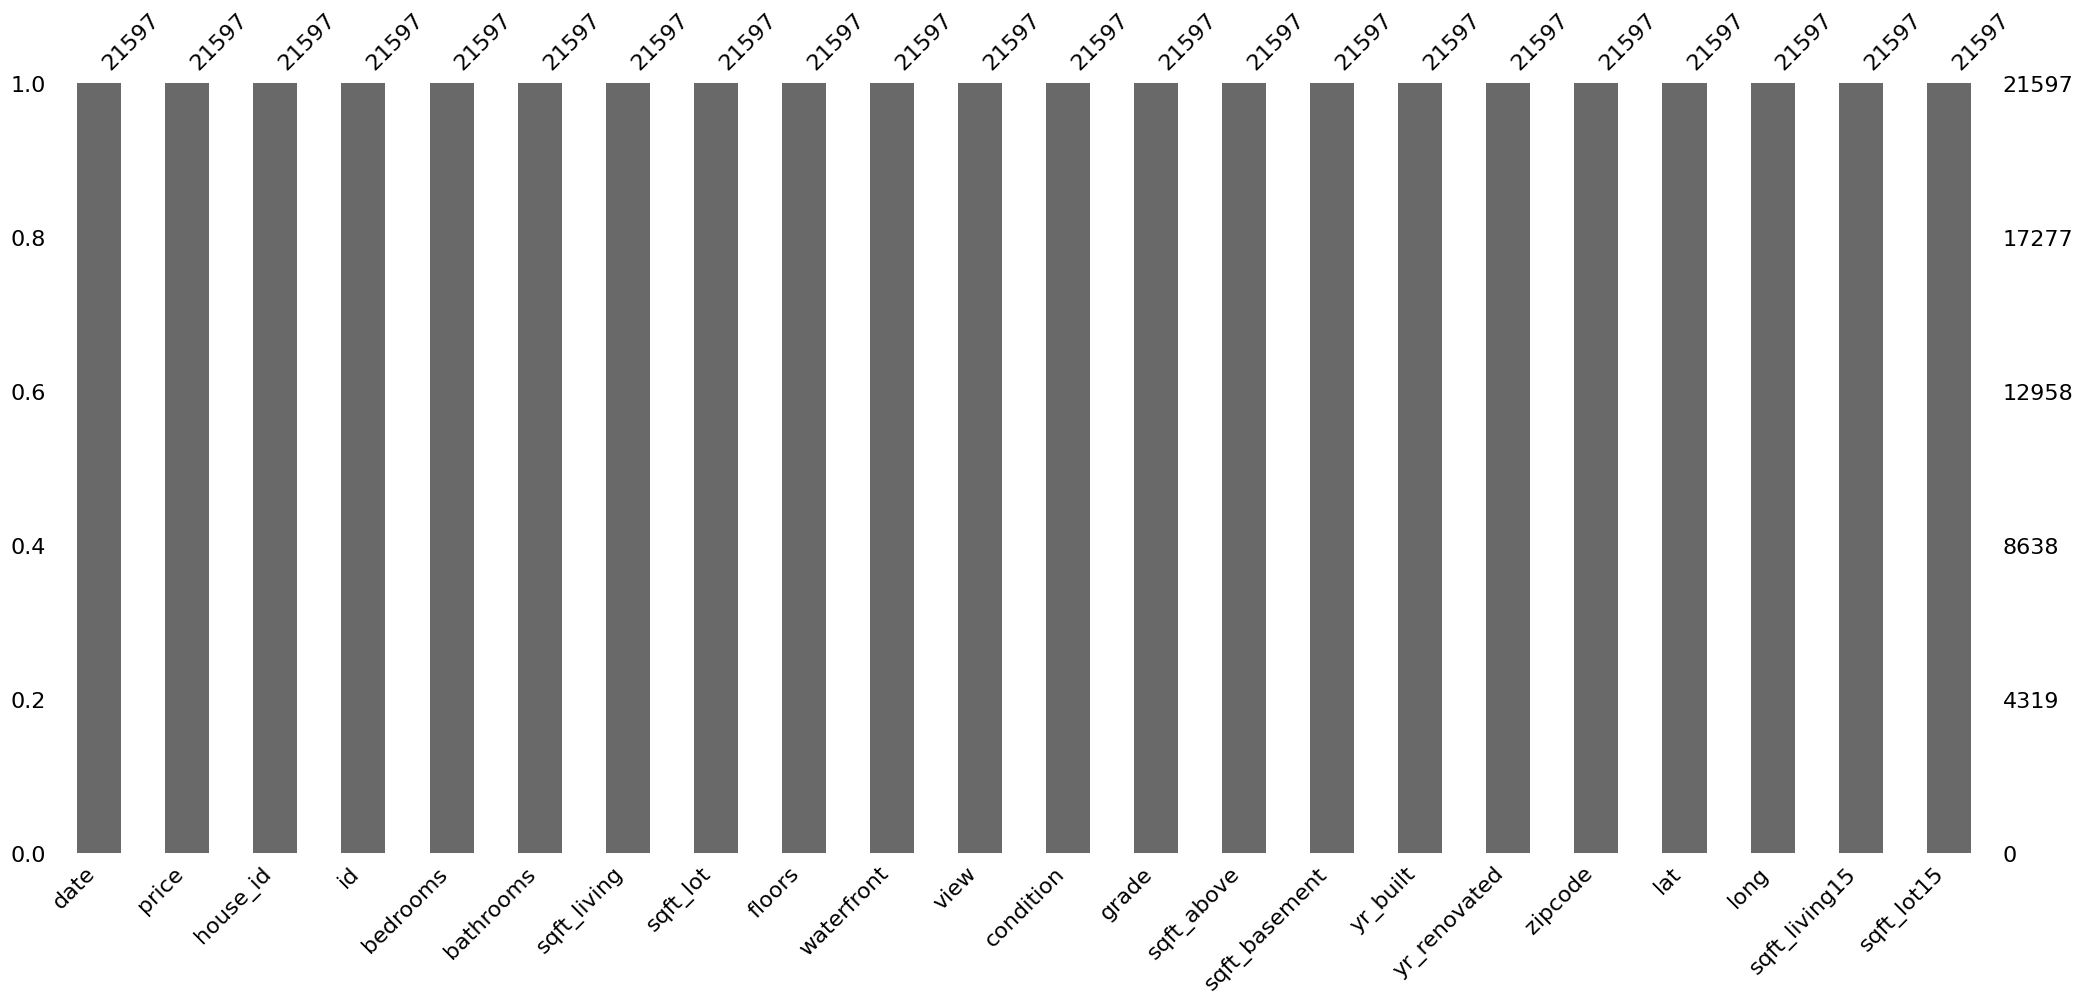

In [35]:
msno.bar(df)

<Axes: >

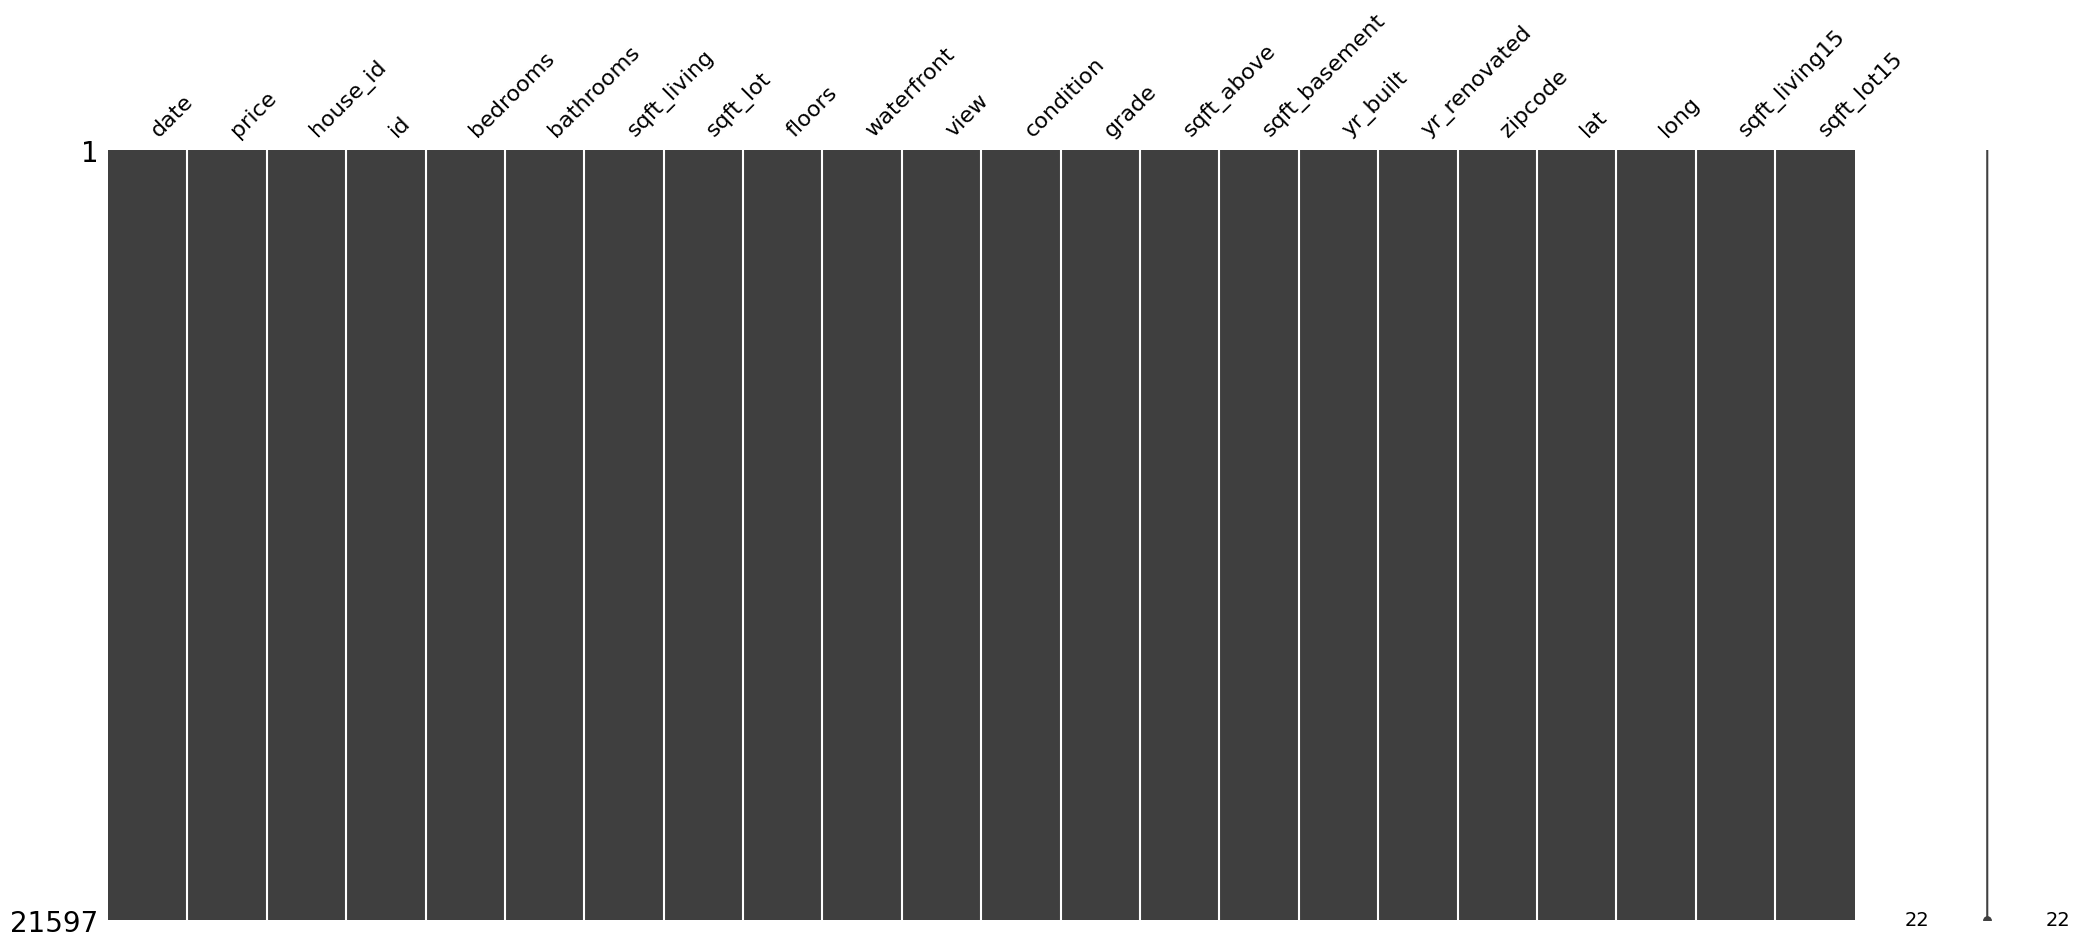

In [36]:
msno.matrix(df)

So we see that there are missing values in the following categories:
* Waterfront
* View
* basement area
* renovation year

#### Waterfront

I feel like the Waterfront should be a boolean and missing values should probably be false because a premium feature like a waterfront view would probably have been explicitly marketed and recorded. 

In [23]:
df['waterfront'] = df['waterfront'].fillna(False).astype(bool)

#### View

There are 63 missing views. Here I will assume as well that, if the view is missing, it might be because it's not good, otherwise such an important selling point would have been mentioned.

In [28]:
df['view'] = df['view'].fillna(0).astype('Int64')

#### Basement Area

Again, here, if the basement area isn't mentioned, that might be that there's no basement at all, so we'll fill it with 0.

In [33]:
df['sqft_basement'] = df['sqft_basement'].fillna(0)

#### Renovation year
For the missing values in the year of renovation, I will suppose it was never renovated. And years should be integer as well.

In [30]:
df['yr_renovated'] = df['yr_renovated'].fillna(0).astype('Int64')

### Other potential problems

There's still a problem with the 'yr_renovated' column. It seems that years have been multiplied by 10. So we can check if there's a remainder 

In [ ]:
# 1. Filter out the 0s and missing values
renovated_houses = df[df['yr_renovated'] > 0]['yr_renovated']

# 2. Check if EVERY single one of them ends in a 0 (remainder is 0 when divided by 10)
all_multiples_of_10 = (renovated_houses % 10 == 0).all()

print(f"Are all non-zero renovation years multiples of 10? {all_multiples_of_10}")

So with that, we can safely divide all the non-missing, non-0 renovation years by 10.

In [ ]:
df.loc[df['yr_renovated'] > 0, 'yr_renovated'] = (df['yr_renovated'] / 10).astype(int)

In [ ]:
df[df['yr_renovated'] > 0]['yr_renovated']

## Business-oriented analysis

### Client: Jennifer Montgomery

### Research question 1: Prestige

"Waterfront homes, with exceptional views and a high-end status, belong to the upper segment of the market."

Let's have a quick look on how the Waterfront, View and Grade distributions look like:

In [66]:
print(df['waterfront'].value_counts())
print(df['grade'].value_counts().sort_index())
print(df['view'].value_counts().sort_index())

waterfront
False    21451
True       146
Name: count, dtype: int64
grade
3        1
4       27
5      242
6     2038
7     8974
8     6065
9     2615
10    1134
11     399
12      89
13      13
Name: count, dtype: int64
view
0    19485
1      330
2      957
3      508
4      317
Name: count, dtype: Int64


Let's see the media price of the houses with and without waterfront:

In [70]:
df.groupby('waterfront')['price'].median().round(2)

waterfront
False    450000.000
True    1510000.000
Name: price, dtype: float64

So, waterfront houses are more than three times mor expensive in median value !

Now, we'll check if the difference is that high for the properties Jennifer might actually be interested in (grade >= 10):

In [71]:
df[df['grade'] >=10 ].groupby('waterfront')['price'].median().round(2)

waterfront
False   1010000.000
True    2510000.000
Name: price, dtype: float64

The factor this time is 2.5, but it's still a big one. So waterfront seems to definitely be a desirability factor.